In [ ]:
# ==============================================================================
# Purpose:
#   Plot spectrum-flow MFI differences (NHB vs NHW) for selected markers across
#   specific immune cell subsets, with per-panel Mann–Whitney p-value (star)
#   annotations, arranged as a single multi-panel grid (rows=cell types,
#   cols=markers) for compact, publication-ready figures.
#
# Steps:
#   1) Load clinical metadata and flow MFI table; harmonize Patient ID formats.
#   2) Merge metadata with MFI features; subset to HR+/HER2- patients.
#   3) Define (celltype × marker) targets and extract matching feature columns.
#   4) Convert wide MFI table to long format; parse feature strings into:
#        - celltype_raw (as encoded in column name)
#        - protein (marker), then rename to biological names (e.g., CD279→PD-1).
#   5) For each (celltype_raw × protein), draw:
#        - boxplot + stripplot by Race & Ethnicity (NHW vs NHB)
#        - Mann–Whitney annotation (stars) with small font in-panel.
#   6) Arrange panels into a single grid (rows=cell types; cols=markers),
#      label y-axis as "MFI" on the first column only, and save to PDF.
#   7) Repeat the same workflow for B-cell homing/activation markers (HLA-DR,
#      CCR7, CXCR5) and save a second figure.
# ==============================================================================

# Header

In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
from math import *
from collections import Counter
import pickle as pkl
import argparse

# import scanpy as sc
# import scvelo as scv

import os
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# import scrublet as scr
import scipy.io
import matplotlib.pyplot as plt

In [2]:
os.chdir('../')

# Load data

In [4]:
import re


def normalize_patient_id(x):
    s = str(x).strip()

    # "31 (M)" → "31-M"
    s = re.sub(r'(\d+)\s*\(([^)]+)\)', r'\1-\2', s)

    # split number and optional suffix
    m = re.match(r'(\d+)(.*)', s)
    if not m:
        return s

    num, suffix = m.groups()
    return f"{int(num):02d}{suffix}"

meta = pd.read_excel(
    'data/12_flow_data_mfi/2025.2.25 IW Invasive clinical metadata.xlsx',
    sheet_name='flow'
)


meta['Patient ID'] = meta['Patient ID'].apply(normalize_patient_id)
meta['Race & Ethnicity'] = (
    meta['Race & Ethnicity']
      .astype(str)
      .str.strip()          # remove leading/trailing spaces and newlines
)

print(Counter(meta['Race & Ethnicity']))
meta

Counter({'NHB': 39, 'NHW': 38})


,Patient ID,Age,Race & Ethnicity,Subtype,Diabetes,Obesity
0,02,34,NHW,"HR+,HER2-",No,No
1,03,74,NHW,"HR+,HER2-",No,Yes
2,04,47,NHB,"HR+,HER2-",No,Yes
3,05,33,NHW,"HR+,HER2+",No,No
4,06,70,NHW,"HR+,HER2-",No,No
...,...,...,...,...,...,...
72,58-E,63,NHW,"HR+,HER2-",No,No
73,06-D,54,NHW,"HR+,HER2+",No,No
74,64-M,46,NHB,"HR+,HER2+",unknown,unknown
75,67-M,55,NHB,"HR+,HER2+",unknown,unknown


In [5]:
df = pd.read_csv('data/12_flow_data_mfi/Ritah_FlowData_Cancer_TB.csv', index_col=0)
df

,[Lymphocytes]|SSC-H|mean,[Total B cells] (CD19+)|SSC-H|mean,{CD20+ B cells}|SSC-H|mean,[DN Memory B]|SSC-H|mean,[Switched Memory B]|SSC-H|mean,[Naive B]|SSC-H|mean,[Unswitched Memory B]|SSC-H|mean,[Plasmablasts] (CD27++/CD38++)|SSC-H|mean,[Total T cells] (CD3+)|SSC-H|mean,[Total T cells] (CD3+)/{CD279+ (PD1)}|SSC-H|mean,...,{CD223+(LAG3) CD3s}|cFluor R840-A___CD3|mean,(DN T cells)|cFluor R840-A___CD3|mean,{Activated CD3+ T cells }|cFluor R840-A___CD3|mean,[ILCs]|cFluor R840-A___CD3|mean,[gdT cells]|cFluor R840-A___CD3|mean,[CD197+/TCRgd+]|cFluor R840-A___CD3|mean,[CD197-/CD45RA-/TCRgd+]|cFluor R840-A___CD3|mean,[CD197-/CD45RA++/TCRgd+]|cFluor R840-A___CD3|mean,[NKT-like cells]|cFluor R840-A___CD3|mean,[Monocytes]|cFluor R840-A___CD3|mean
file,,,,,,,,,,,,,,,,,,,,,
[fcs - invasive TB] 02.fcs,326693,314196,310763,308520,371870,280443,349551,431461,320518,340260,...,3.94,4.12,3.52,0.1190,4.31,3.85,4.64,3.96,3.70,0.4420
[fcs - invasive TB] 03.fcs,317031,330387,328895,327990,380465,300785,367460,403124,301117,339646,...,3.71,3.72,3.32,0.1850,3.93,3.90,4.21,3.95,3.49,0.5870
[fcs - invasive TB] 4.fcs,363118,329074,328393,322179,404915,314509,368956,397933,350298,365571,...,3.58,3.72,3.54,0.0306,3.89,3.63,4.36,3.77,3.54,0.0899
[fcs - invasive TB] 05.fcs,340302,333870,330845,294899,367407,285994,363583,402924,325342,349967,...,3.85,4.15,3.55,0.2810,4.40,3.88,4.64,4.04,3.72,0.7070
[fcs - invasive TB] 06-D.fcs,373503,387301,387403,345360,401728,358387,401799,456647,363724,375532,...,3.62,3.11,3.38,0.0980,3.47,3.61,3.36,3.64,3.48,0.4370
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
[fcs - invasive TB] 100.fcs,349652,295326,296097,298859,372107,288233,361204,424285,315068,329626,...,3.44,2.95,2.90,0.0951,3.42,3.16,4.03,3.31,3.36,0.2780
[fcs - invasive TB] 101.fcs,324545,290998,288512,307951,349113,256343,330057,466701,309359,320973,...,3.40,3.19,3.14,0.0515,3.56,3.48,3.80,3.41,3.22,0.4870
[fcs - invasive TB] 104.fcs,348574,312468,312690,316238,392194,294713,366755,405869,339227,355325,...,3.87,3.67,3.49,0.1080,4.06,3.93,4.36,4.27,3.76,0.7170


In [6]:
df['Patient ID'] = (
    df.index.astype(str)
    .str.extract(r'\]\s*([^\.\s]+)\.fcs', expand=False)
)

df['Patient ID'] = (
    df['Patient ID'].astype(str)
      .str.replace(r'^(\d)(\D|$)', r'0\1\2', regex=True)
).tolist()

df['Patient ID']

file
[fcs - invasive TB] 02.fcs        02
[fcs - invasive TB] 03.fcs        03
[fcs - invasive TB] 4.fcs         04
[fcs - invasive TB] 05.fcs        05
[fcs - invasive TB] 06-D.fcs    06-D
                                ... 
[fcs - invasive TB] 100.fcs      100
[fcs - invasive TB] 101.fcs      101
[fcs - invasive TB] 104.fcs      104
[fcs - invasive TB] 106.fcs      106
[fcs - invasive TB] 108.fcs      108
Name: Patient ID, Length: 77, dtype: object

In [7]:
dfp = pd.merge(
    meta, df,
    on='Patient ID'
)

dfp

,Patient ID,Age,Race & Ethnicity,Subtype,Diabetes,Obesity,[Lymphocytes]|SSC-H|mean,[Total B cells] (CD19+)|SSC-H|mean,{CD20+ B cells}|SSC-H|mean,[DN Memory B]|SSC-H|mean,...,{CD223+(LAG3) CD3s}|cFluor R840-A___CD3|mean,(DN T cells)|cFluor R840-A___CD3|mean,{Activated CD3+ T cells }|cFluor R840-A___CD3|mean,[ILCs]|cFluor R840-A___CD3|mean,[gdT cells]|cFluor R840-A___CD3|mean,[CD197+/TCRgd+]|cFluor R840-A___CD3|mean,[CD197-/CD45RA-/TCRgd+]|cFluor R840-A___CD3|mean,[CD197-/CD45RA++/TCRgd+]|cFluor R840-A___CD3|mean,[NKT-like cells]|cFluor R840-A___CD3|mean,[Monocytes]|cFluor R840-A___CD3|mean
0,02,34,NHW,"HR+,HER2-",No,No,326693,314196,310763,308520,...,3.94,4.12,3.52,0.1190,4.31,3.85,4.64,3.96,3.70,0.4420
1,03,74,NHW,"HR+,HER2-",No,Yes,317031,330387,328895,327990,...,3.71,3.72,3.32,0.1850,3.93,3.90,4.21,3.95,3.49,0.5870
2,04,47,NHB,"HR+,HER2-",No,Yes,363118,329074,328393,322179,...,3.58,3.72,3.54,0.0306,3.89,3.63,4.36,3.77,3.54,0.0899
3,05,33,NHW,"HR+,HER2+",No,No,340302,333870,330845,294899,...,3.85,4.15,3.55,0.2810,4.40,3.88,4.64,4.04,3.72,0.7070
4,06,70,NHW,"HR+,HER2-",No,No,351580,364773,363156,368835,...,3.71,3.78,3.50,0.3470,3.98,3.88,3.80,4.15,3.46,0.5420
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,58-E,63,NHW,"HR+,HER2-",No,No,331136,328876,328376,291783,...,3.94,3.92,3.67,0.1020,4.08,3.95,4.54,3.78,3.73,0.2920
73,06-D,54,NHW,"HR+,HER2+",No,No,373503,387301,387403,345360,...,3.62,3.11,3.38,0.0980,3.47,3.61,3.36,3.64,3.48,0.4370
74,64-M,46,NHB,"HR+,HER2+",unknown,unknown,340364,344670,344726,344224,...,3.54,3.64,3.58,0.0224,3.88,3.54,4.32,4.17,3.51,0.0605
75,67-M,55,NHB,"HR+,HER2+",unknown,unknown,354113,312633,312234,330315,...,3.55,3.41,3.37,-0.0454,3.67,3.69,3.55,3.86,3.38,0.0548


In [8]:
dfp = dfp[
(dfp['Subtype']=='HR+,HER2-')
]

In [9]:
flowmarker_df = pd.DataFrame({
    'celltype': [
        col.split('|')[0][1:-1]
        for col in df.columns
        if col != 'Patient ID'
    ],
    'antibody': [
        col.split('|')[1]
        for col in df.columns
        if col != 'Patient ID'
    ]
})

flowmarker_df = flowmarker_df[
    ~flowmarker_df['antibody'].str.startswith(('SSC', 'FSC','ViaDye'))
]

flowmarker_df['antibody'] = [x.split('___')[1] for x in flowmarker_df['antibody']]
flowmarker_df

,celltype,antibody
462,Lymphocytes,CD194
463,Total B cells] (CD19+,CD194
464,CD20+ B cells,CD194
465,DN Memory B,CD194
466,Switched Memory B,CD194
...,...,...
2536,CD197+/TCRgd+,CD3
2537,CD197-/CD45RA-/TCRgd+,CD3
2538,CD197-/CD45RA++/TCRgd+,CD3
2539,NKT-like cells,CD3


In [10]:
Counter(flowmarker_df['antibody'])

Counter({'CD194': 77,
         'IgD': 77,
         'CD223': 77,
         'TCRab': 77,
         'CD20': 77,
         'CD161': 77,
         'CD27': 77,
         'CD127': 77,
         'CD28': 77,
         'CD8': 77,
         'CD279': 77,
         'CD45': 77,
         'CD196': 77,
         'CD185': 77,
         'CD25': 77,
         'CD4': 77,
         'CD152': 77,
         'CD19': 77,
         'CD366': 77,
         'TCRgd': 77,
         'CD197': 77,
         'CD183': 77,
         'CD45RA': 77,
         'CD38': 77,
         'HLA-DR': 77,
         'CD3': 77})

# CD4 T

In [29]:
comb = [
    (x,y) for x in [
        '[Naive CD4]',
        '[Central Memory CD4]',
        '[Effector CD4]',
        '[Tregs] (CD25+/CD127lo'
    ] for y in [
        'HLA-DR',
        'CD279',
        'CD152',
        'CD366',
        'CD223'
    ]
]
comb

[('[Naive CD4]', 'HLA-DR'),
 ('[Naive CD4]', 'CD279'),
 ('[Naive CD4]', 'CD152'),
 ('[Naive CD4]', 'CD366'),
 ('[Naive CD4]', 'CD223'),
 ('[Central Memory CD4]', 'HLA-DR'),
 ('[Central Memory CD4]', 'CD279'),
 ('[Central Memory CD4]', 'CD152'),
 ('[Central Memory CD4]', 'CD366'),
 ('[Central Memory CD4]', 'CD223'),
 ('[Effector CD4]', 'HLA-DR'),
 ('[Effector CD4]', 'CD279'),
 ('[Effector CD4]', 'CD152'),
 ('[Effector CD4]', 'CD366'),
 ('[Effector CD4]', 'CD223'),
 ('[Tregs] (CD25+/CD127lo', 'HLA-DR'),
 ('[Tregs] (CD25+/CD127lo', 'CD279'),
 ('[Tregs] (CD25+/CD127lo', 'CD152'),
 ('[Tregs] (CD25+/CD127lo', 'CD366'),
 ('[Tregs] (CD25+/CD127lo', 'CD223')]

In [30]:
import re

cols_sel = [
    col for col in df.columns
    if col != 'Patient ID'
    and any(
        col.split('|')[0]==ct and (mk in col.split('|')[-2])
        for ct, mk in comb
    )
]

cols_sel = sorted(
    cols_sel,
    key=lambda c: next(
        i for i, (ct, mk) in enumerate(comb)
        if c.startswith(ct) and mk in c.split('|')[-2]
    )
)

cols_sel

['[Naive CD4]|cFluor R780-A___HLA-DR|mean',
 '[Naive CD4]|BB515-A___CD279|mean',
 '[Naive CD4]|PE-Dazzle594-A___CD152|mean',
 '[Naive CD4]|cFluor BYG667-A___CD366|mean',
 '[Naive CD4]|BV480-A___CD223|mean',
 '[Central Memory CD4]|cFluor R780-A___HLA-DR|mean',
 '[Central Memory CD4]|BB515-A___CD279|mean',
 '[Central Memory CD4]|PE-Dazzle594-A___CD152|mean',
 '[Central Memory CD4]|cFluor BYG667-A___CD366|mean',
 '[Central Memory CD4]|BV480-A___CD223|mean',
 '[Effector CD4]|cFluor R780-A___HLA-DR|mean',
 '[Effector CD4]|BB515-A___CD279|mean',
 '[Effector CD4]|PE-Dazzle594-A___CD152|mean',
 '[Effector CD4]|cFluor BYG667-A___CD366|mean',
 '[Effector CD4]|BV480-A___CD223|mean',
 '[Tregs] (CD25+/CD127lo|cFluor R780-A___HLA-DR|mean',
 '[Tregs] (CD25+/CD127lo|BB515-A___CD279|mean',
 '[Tregs] (CD25+/CD127lo|PE-Dazzle594-A___CD152|mean',
 '[Tregs] (CD25+/CD127lo|cFluor BYG667-A___CD366|mean',
 '[Tregs] (CD25+/CD127lo|BV480-A___CD223|mean']

In [31]:
from statannotations.Annotator import Annotator
import matplotlib.pyplot as plt
import seaborn as sns

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:3.029e-02 U_stat=1.490e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:3.918e-02 U_stat=1.535e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:5.292e-06 U_stat=4.400e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    *

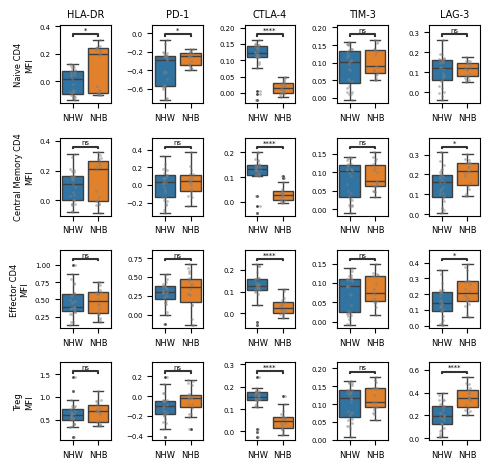

In [32]:
# assumes:
# - cols_sel already exists
# - dfp exists
# - Annotator imported
# - seaborn / matplotlib imported

# ---------------- protein renaming ----------------
protein_map = {

    'CD274': 'PD-L1',
    'CD38':  'CD38',
    
    'HLA-DR': 'HLA-DR',
    'CD279': 'PD-1',
    'CD152': 'CTLA-4',
    'CD366': 'TIM-3',
    'CD223': 'LAG-3'
    
}

id_cols = ['Patient ID', 'Age', 'Race & Ethnicity', 'Subtype', 'Diabetes', 'Obesity']

# -------- wide -> long --------
long = (
    dfp.loc[:, id_cols + cols_sel]
       .melt(id_vars=id_cols, value_vars=cols_sel,
             var_name='feature', value_name='value')
)

parts = long['feature'].astype(str).str.split('|')
long['celltype_raw'] = parts.str[0].str.strip()
long['celltype'] = parts.str[0].str.strip().str.strip('[]')
long['channel'] = parts.str[1].str.strip()
long['protein'] = long['channel'].str.split('___').str[-1]

# rename proteins to biological names
long['protein'] = long['protein'].map(lambda x: protein_map.get(x, x))

long['Race & Ethnicity'] = long['Race & Ethnicity'].astype(str).str.strip()

order = ['NHW', 'NHB']
pairs = [('NHW', 'NHB')]

# -------- layout: rows = cell types, cols = proteins --------
cell_order = pd.unique(long['celltype_raw'])
prot_order = pd.unique(long['protein'])

nrows = len(cell_order)
ncols = len(prot_order)

fig, axs = plt.subplots(
    nrows=nrows, ncols=ncols,
    figsize=(1 * ncols, 1.2 * nrows),  # short panels
    sharex=False, sharey=False
)

for i, cell_raw in enumerate(cell_order):
    for j, prot in enumerate(prot_order):
        ax = axs[i, j] if nrows > 1 else axs[j]

        tmp = long[
            (long['celltype_raw'] == cell_raw) &
            (long['protein'] == prot)
        ]

        if tmp.empty:
            ax.axis('off')
            continue

        sns.boxplot(
            data=tmp, x='Race & Ethnicity', y='value',
            hue='Race & Ethnicity', order=order,
            dodge=False, ax=ax, fliersize=1
        )
        sns.stripplot(
            data=tmp, x='Race & Ethnicity', y='value',
            order=order, color='gray',
            size=2, alpha=.5, dodge=False, ax=ax
        )

        annot = Annotator(
            ax, pairs, data=tmp,
            x='Race & Ethnicity', y='value', order=order
        )
        annot.configure(
            test='Mann-Whitney',
            text_format='star',
            loc='inside',
            show_test_name=False,
            fontsize=5 
        )
        annot.apply_and_annotate()

        if ax.get_legend() is not None:
            ax.legend_.remove()

        # titles only on top row
        if i == 0:
            ax.set_title(prot, fontsize=7)

        # y-label only on first column
        if j == 0:
            pretty = cell_raw.replace('[Tregs] (CD25+/CD127lo', 'Treg').strip('[]')
            ax.set_ylabel(f'{pretty}\nMFI', fontsize=6)
        else:
            ax.set_ylabel('')

        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=6)
        ax.tick_params(axis='y', labelsize=5)

plt.tight_layout()
plt.savefig('plots/S7_3/MFI_CD4T.pdf',
            bbox_inches='tight')
plt.show()

# B cells

In [34]:
comb = [
    (x,y) for x in [
        '[Naive B]',
        '{CD20+ B cells}',
        '[Unswitched Memory B]',
        '[Switched Memory B]',
        '[Plasmablasts]'
    ] for y in [
        'HLA-DR',
        'CD197',
        'CD185'
    ]
]
comb

[('[Naive B]', 'HLA-DR'),
 ('[Naive B]', 'CD197'),
 ('[Naive B]', 'CD185'),
 ('{CD20+ B cells}', 'HLA-DR'),
 ('{CD20+ B cells}', 'CD197'),
 ('{CD20+ B cells}', 'CD185'),
 ('[Unswitched Memory B]', 'HLA-DR'),
 ('[Unswitched Memory B]', 'CD197'),
 ('[Unswitched Memory B]', 'CD185'),
 ('[Switched Memory B]', 'HLA-DR'),
 ('[Switched Memory B]', 'CD197'),
 ('[Switched Memory B]', 'CD185'),
 ('[Plasmablasts]', 'HLA-DR'),
 ('[Plasmablasts]', 'CD197'),
 ('[Plasmablasts]', 'CD185')]

In [35]:
import re

cols_sel = [
    col for col in df.columns
    if col != 'Patient ID'
    and any(
        col.split('|')[0]==ct and (mk in col.split('|')[-2])
        for ct, mk in comb
    )
]

cols_sel = sorted(
    cols_sel,
    key=lambda c: next(
        i for i, (ct, mk) in enumerate(comb)
        if c.startswith(ct) and mk in c.split('|')[-2]
    )
)

cols_sel

['[Naive B]|cFluor R780-A___HLA-DR|mean',
 '[Naive B]|cFluor BYG781-A___CD197|mean',
 '[Naive B]|PerCP-eFluor 710-A___CD185|mean',
 '{CD20+ B cells}|cFluor R780-A___HLA-DR|mean',
 '{CD20+ B cells}|cFluor BYG781-A___CD197|mean',
 '{CD20+ B cells}|PerCP-eFluor 710-A___CD185|mean',
 '[Unswitched Memory B]|cFluor R780-A___HLA-DR|mean',
 '[Unswitched Memory B]|cFluor BYG781-A___CD197|mean',
 '[Unswitched Memory B]|PerCP-eFluor 710-A___CD185|mean',
 '[Switched Memory B]|cFluor R780-A___HLA-DR|mean',
 '[Switched Memory B]|cFluor BYG781-A___CD197|mean',
 '[Switched Memory B]|PerCP-eFluor 710-A___CD185|mean']

In [36]:
from statannotations.Annotator import Annotator
import matplotlib.pyplot as plt
import seaborn as sns

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:9.522e-02 U_stat=3.155e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:2.049e-03 U_stat=3.765e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:1.010e-02 U_stat=3.545e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    *

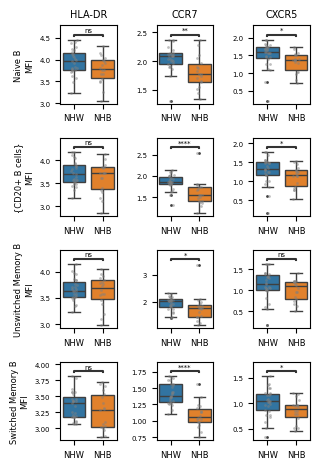

In [37]:
# assumes:
# - cols_sel already exists
# - dfp exists
# - Annotator imported
# - seaborn / matplotlib imported

# ---------------- protein renaming ----------------
protein_map = {
    
    'HLA-DR': 'HLA-DR',
    'CD197': 'CCR7',
    'CD185': 'CXCR5'
    
}

id_cols = ['Patient ID', 'Age', 'Race & Ethnicity', 'Subtype', 'Diabetes', 'Obesity']

# -------- wide -> long --------
long = (
    dfp.loc[:, id_cols + cols_sel]
       .melt(id_vars=id_cols, value_vars=cols_sel,
             var_name='feature', value_name='value')
)

parts = long['feature'].astype(str).str.split('|')
long['celltype_raw'] = parts.str[0].str.strip()
long['celltype'] = parts.str[0].str.strip().str.strip('[]')
long['channel'] = parts.str[1].str.strip()
long['protein'] = long['channel'].str.split('___').str[-1]

# rename proteins to biological names
long['protein'] = long['protein'].map(lambda x: protein_map.get(x, x))

long['Race & Ethnicity'] = long['Race & Ethnicity'].astype(str).str.strip()

order = ['NHW', 'NHB']
pairs = [('NHW', 'NHB')]

# -------- layout: rows = cell types, cols = proteins --------
cell_order = pd.unique(long['celltype_raw'])
prot_order = pd.unique(long['protein'])

nrows = len(cell_order)
ncols = len(prot_order)

fig, axs = plt.subplots(
    nrows=nrows, ncols=ncols,
    figsize=(1.1 * ncols, 1.2 * nrows),  # short panels
    sharex=False, sharey=False
)

for i, cell_raw in enumerate(cell_order):
    for j, prot in enumerate(prot_order):
        ax = axs[i, j] if nrows > 1 else axs[j]

        tmp = long[
            (long['celltype_raw'] == cell_raw) &
            (long['protein'] == prot)
        ]

        if tmp.empty:
            ax.axis('off')
            continue

        sns.boxplot(
            data=tmp, x='Race & Ethnicity', y='value',
            hue='Race & Ethnicity', order=order,
            dodge=False, ax=ax, fliersize=1
        )
        sns.stripplot(
            data=tmp, x='Race & Ethnicity', y='value',
            order=order, color='gray',
            size=2, alpha=.5, dodge=False, ax=ax
        )

        annot = Annotator(
            ax, pairs, data=tmp,
            x='Race & Ethnicity', y='value', order=order
        )
        annot.configure(
            test='Mann-Whitney',
            text_format='star',
            loc='inside',
            show_test_name=False,
            fontsize=5 
        )
        annot.apply_and_annotate()

        if ax.get_legend() is not None:
            ax.legend_.remove()

        # titles only on top row
        if i == 0:
            ax.set_title(prot, fontsize=7)

        # y-label only on first column
        if j == 0:
            pretty = cell_raw.replace('[Tregs] (CD25+/CD127lo', 'Treg').strip('[]')
            ax.set_ylabel(f'{pretty}\nMFI', fontsize=6)
        else:
            ax.set_ylabel('')

        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=6)
        ax.tick_params(axis='y', labelsize=5)

plt.tight_layout()
plt.savefig('plots/S7_3/MFI_Bcells.pdf',
            bbox_inches='tight')
plt.show()